# Hipótese 4: Aumento de Alarmes Antes da Manutenção Corretiva

## 1. Contexto Teórico e Problematização

As Portas de Plataforma (PSDs) operam sob ciclos intensivos de acionamento e estão sujeitas a falhas mecânicas, elétricas e de controle ao longo do tempo. Uma hipótese comum em manutenção preditiva é que, antes de uma falha que exige intervenção corretiva, o equipamento já vinha "avisando" o problema através de um volume crescente de alarmes.

Para isolar esse efeito dos ruídos operacionais do dia a dia, o estudo exclui os alarmes classificados como `OBS` (obstruções por passageiros/objetos), cuja causa é comportamental e não mecânica.

* **H4.1 (Aumento de alarmes antes da manutenção):** O volume de alarmes não-OBS aumenta no intervalo imediatamente anterior à ordem de manutenção corretiva, em comparação ao intervalo equivalente posterior à intervenção.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['figure.dpi'] = 120

COR_ANTES = '#e15759'
COR_DEPOIS = '#4c78a8'

# 1. Carregamento das bases
ordens = pd.read_excel('../../data/Ordens do SAP - Corretiva emergencial (ZM01).XLSX')
alarmes = pd.read_excel('../../data/Alarmes do sistema de PSD.xlsx')

print(f"Ordens corretivas (ZM01) carregadas: {len(ordens):,}")
print(f"Alarmes carregados: {len(alarmes):,}")


Ordens corretivas (ZM01) carregadas: 10,647
Alarmes carregados: 150,003


## 2. Metodologia de Análise

A versão inicial desta análise comparava o volume de alarmes de **todo o sistema de PSD** antes e depois de cada ordem de manutenção, sem considerar a estação em que a falha realmente ocorreu. Isso mistura o comportamento de portas que nada têm a ver com a ordem analisada, diluindo qualquer sinal real de degradação local.

Para corrigir esse problema, a metodologia foi refeita com os seguintes critérios:

1. **Timestamp da falha:** concatenação de data e hora de início da avaria (`Início avaria` + `Hora início avaria`).
2. **Pareamento por estação:** o código da estação é extraído do campo `Local de Instalação` (ex.: `SP04-6-PSD-BUT-P1S1` → estação `BUT`) e usado para filtrar **apenas os alarmes da mesma estação** da ordem, em vez do sistema inteiro.
3. **Filtragem de ruído:** exclusão de todos os alarmes `OBS`.
4. **Cobertura de dados:** cada ordem só é incluída se a janela de comparação (antes e depois) estiver totalmente contida no período coberto pela base de alarmes, evitando subcontagem artificial nas bordas do dataset.
5. **Múltiplas janelas:** comparação em janelas de 1, 3, 7 e 14 dias, para verificar se o efeito é imediato, de curto prazo ou persistente.
6. **Teste estatístico pareado:** cada ordem gera um par (alarmes antes, alarmes depois). Como a mesma "unidade" é medida duas vezes, o teste apropriado é o **teste de Wilcoxon (signed-rank, pareado)**, complementado por um **teste binomial** sobre a proporção de ordens em que "antes" supera "depois".


In [2]:
# 2. Preparação das datas e extração da estação
ordens['DataInicio'] = pd.to_datetime(
    ordens['Início avaria'].astype(str) + ' ' + ordens['Hora início avaria'].astype(str),
    format='%d/%m/%Y %H:%M:%S', errors='coerce'
)
ordens = ordens.dropna(subset=['DataInicio']).copy()
ordens['Estacao'] = ordens['Local de Instalação'].astype(str).str.split('-').str[3]

# Remover ordens duplicadas (mesma estação + mesmo instante de início da avaria)
ordens = ordens.drop_duplicates(subset=['Estacao', 'DataInicio']).copy()

alarmes['Horário do Alarme'] = pd.to_datetime(alarmes['Horário do Alarme'], errors='coerce')
alarmes_validos = alarmes[alarmes['Alarme'].astype(str).str.upper() != 'OBS'].copy()

print("Distribuição de ordens por estação:")
print(ordens['Estacao'].value_counts())


Distribuição de ordens por estação:
Estacao
REP    1567
PTA    1273
PIN    1265
FRA    1020
HIG     904
FAL     882
FRE     780
BUT     765
MBI     671
LUZ     615
VSO     439
PVS      21
Name: count, dtype: int64


### 2.1 Achado crítico: cobertura desigual de alarmes por estação

Antes de comparar antes/depois, é essencial checar se todas as estações realmente possuem histórico de alarmes não-OBS. A tabela cruzada abaixo mostra a contagem de cada tipo de alarme por estação.


In [3]:
tabela_cobertura = pd.crosstab(alarmes['Estação'], alarmes['Alarme'])
display(tabela_cobertura)

estacoes_com_falha_registrada = alarmes_validos['Estação'].dropna().unique().tolist()
print(f"\nEstações com alarmes técnicos (não-OBS) registrados: {estacoes_com_falha_registrada}")


Alarme,CA,CSD,FC,FO,LSD,OA,OBS,STS
Estação,,,,,,,,
BUT,4168,4102,4437,4617,4606,4128,18334,12822
FAL,0,0,0,0,0,0,17079,0
FRA,0,0,0,0,0,0,28406,0
FRE,0,0,0,0,0,0,8399,0
HIG,0,0,0,0,0,0,24385,0
LUZ,0,0,0,0,0,0,14517,0



Estações com alarmes técnicos (não-OBS) registrados: ['BUT']


**Apenas a estação `BUT` possui alarmes técnicos (`CA`, `CSD`, `FC`, `FO`, `LSD`, `OA`, `STS`) registrados na base.** As demais cinco estações (`FAL`, `FRA`, `FRE`, `HIG`, `LUZ`) só têm eventos `OBS`, que já são removidos pela definição da hipótese.

Isso significa que a análise "antes vs. depois" só pode ser conduzida de forma válida para as ordens de manutenção da estação `BUT`, para as demais estações, contar "alarmes não-OBS" resultaria sempre em zero, o que enviesaria qualquer comparação agregada. A análise a seguir é, portanto, restrita a `BUT`, e essa limitação é retomada na seção de conclusões.


In [4]:
# 3. Restringir a análise à estação com cobertura de alarmes técnicos
ordens_but = ordens[ordens['Estacao'] == 'BUT'].copy()
alarmes_but = alarmes_validos[alarmes_validos['Estação'] == 'BUT'].copy()

cobertura_inicio = alarmes_but['Horário do Alarme'].min()
cobertura_fim = alarmes_but['Horário do Alarme'].max()

print(f"Ordens corretivas na estação BUT: {len(ordens_but):,}")
print(f"Cobertura da base de alarmes (BUT): {cobertura_inicio} até {cobertura_fim}")

# Vetor ordenado de timestamps de alarme, para contagem eficiente por busca binária
timestamps_alarme = np.sort(alarmes_but['Horário do Alarme'].values.astype('datetime64[ns]'))

def contar_no_intervalo(inicio, fim):
    lo = np.searchsorted(timestamps_alarme, np.datetime64(inicio), side='left')
    hi = np.searchsorted(timestamps_alarme, np.datetime64(fim), side='left')
    return hi - lo


Ordens corretivas na estação BUT: 765
Cobertura da base de alarmes (BUT): 2023-10-19 10:24:35.800000 até 2026-05-12 05:52:14.727000


In [5]:
# 4. Contagem antes/depois por janela, com teste pareado
janelas_dias = [1, 3, 7, 14]
resumo = []
distribuicoes = {}

for janela in janelas_dias:
    dt = pd.Timedelta(days=janela)
    cobre_janela = (ordens_but['DataInicio'] - dt >= cobertura_inicio) & (ordens_but['DataInicio'] + dt <= cobertura_fim)
    sub = ordens_but.loc[cobre_janela, 'DataInicio']

    antes = np.array([contar_no_intervalo(t - dt, t) for t in sub])
    depois = np.array([contar_no_intervalo(t, t + dt) for t in sub])
    distribuicoes[janela] = (antes, depois)

    n_antes_maior = int(np.sum(antes > depois))
    n_depois_maior = int(np.sum(antes < depois))
    n_empate = int(np.sum(antes == depois))

    _, wilcoxon_p = stats.wilcoxon(antes, depois) if np.any(antes != depois) else (np.nan, np.nan)
    binom_p = stats.binomtest(n_antes_maior, n_antes_maior + n_depois_maior, p=0.5).pvalue if (n_antes_maior + n_depois_maior) > 0 else np.nan

    resumo.append({
        'janela_dias': janela,
        'n_ordens': len(sub),
        'media_antes': antes.mean(),
        'media_depois': depois.mean(),
        'mediana_antes': float(np.median(antes)),
        'mediana_depois': float(np.median(depois)),
        'pct_antes_maior': n_antes_maior / len(sub) * 100,
        'pct_depois_maior': n_depois_maior / len(sub) * 100,
        'pct_empate': n_empate / len(sub) * 100,
        'wilcoxon_p': wilcoxon_p,
        'binom_p': binom_p,
    })

resumo_df = pd.DataFrame(resumo)
display(resumo_df.style.format({
    'media_antes': '{:.1f}', 'media_depois': '{:.1f}',
    'mediana_antes': '{:.1f}', 'mediana_depois': '{:.1f}',
    'pct_antes_maior': '{:.1f}%', 'pct_depois_maior': '{:.1f}%', 'pct_empate': '{:.1f}%',
    'wilcoxon_p': '{:.4f}', 'binom_p': '{:.4f}',
}))


,janela_dias,n_ordens,media_antes,media_depois,mediana_antes,mediana_depois,pct_antes_maior,pct_depois_maior,pct_empate,wilcoxon_p,binom_p
0,1,620,35.7,35.6,7.0,8.0,37.1%,42.7%,20.2%,0.3895,0.1264
1,3,617,100.0,104.6,39.0,38.0,43.4%,46.4%,10.2%,0.2587,0.4702
2,7,613,232.6,244.1,143.0,142.0,49.3%,47.6%,3.1%,0.6265,0.7120
3,14,607,446.5,498.5,289.0,325.0,44.5%,55.4%,0.2%,0.0012,0.0082


## 3. Resultados e Interpretação

### 3.1 Medianas de alarmes por janela temporal

O gráfico abaixo compara a mediana de alarmes não-OBS antes e depois da ordem de manutenção, para cada janela avaliada. A mediana é usada em vez da média porque a distribuição de alarmes por ordem é fortemente assimétrica (poucas ordens concentram picos muito altos de alarmes).


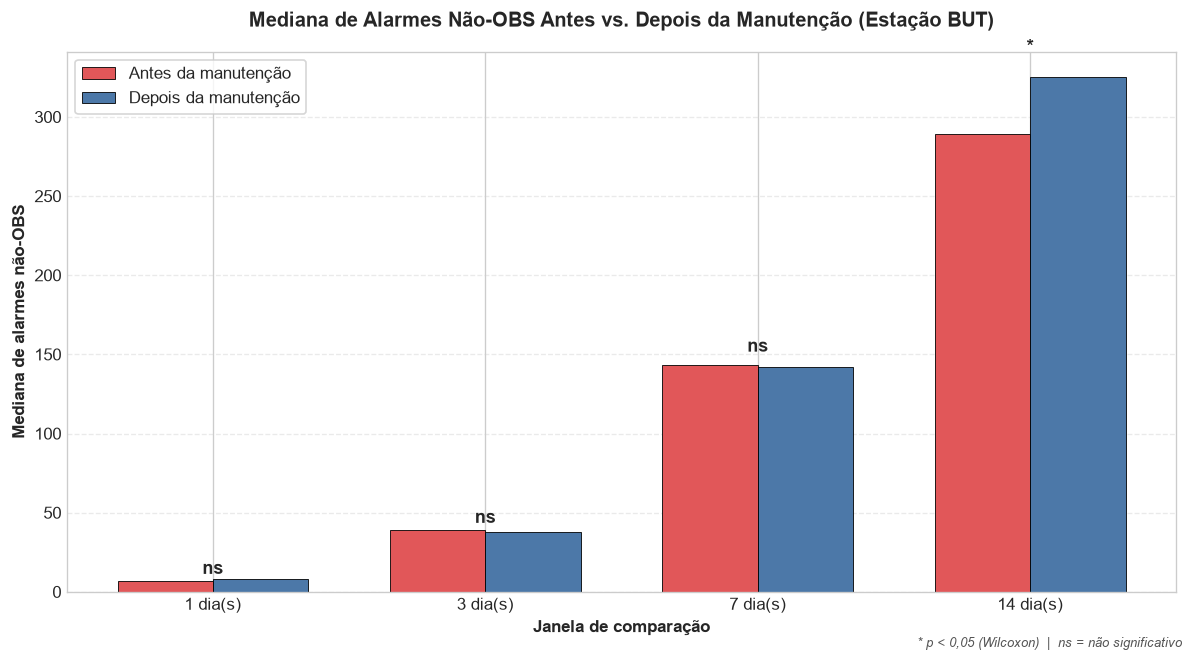

In [6]:
fig, ax = plt.subplots(figsize=(10, 5.5))
x = np.arange(len(resumo_df))
largura = 0.35

barras_antes = ax.bar(x - largura/2, resumo_df['mediana_antes'], largura, label='Antes da manutenção', color=COR_ANTES, edgecolor='black', linewidth=0.5)
barras_depois = ax.bar(x + largura/2, resumo_df['mediana_depois'], largura, label='Depois da manutenção', color=COR_DEPOIS, edgecolor='black', linewidth=0.5)

for i, row in resumo_df.iterrows():
    marcador = '*' if row['wilcoxon_p'] < 0.05 else 'ns'
    y_max = max(row['mediana_antes'], row['mediana_depois'])
    ax.text(i, y_max + y_max * 0.04 + 3, marcador, ha='center', fontsize=11, fontweight='bold')

ax.set_xticks(x)
ax.set_xticklabels([f"{j} dia(s)" for j in resumo_df['janela_dias']])
ax.set_xlabel('Janela de comparação', fontsize=10, fontweight='bold')
ax.set_ylabel('Mediana de alarmes não-OBS', fontsize=10, fontweight='bold')
ax.set_title('Mediana de Alarmes Não-OBS Antes vs. Depois da Manutenção (Estação BUT)', fontsize=12, fontweight='bold', pad=15)
ax.legend(loc='upper left', frameon=True, facecolor='white')
ax.grid(axis='y', linestyle='--', alpha=0.4)
plt.figtext(0.99, 0.01, '* p < 0,05 (Wilcoxon)  |  ns = não significativo', ha='right', fontsize=8, style='italic', color='#555555')
plt.tight_layout()
plt.savefig('../../docs/src/assets/sprints/sprint1/hipotese4-medianas-janelas.png', dpi=150, bbox_inches='tight')
plt.show()


### 3.2 Distribuição completa: antes vs. depois (janela de 14 dias)

As medianas e médias escondem a forma da distribuição. O boxplot a seguir mostra a dispersão completa de contagens de alarme por ordem na janela de 14 dias, a única em que a diferença antes/depois se mostrou estatisticamente significativa.


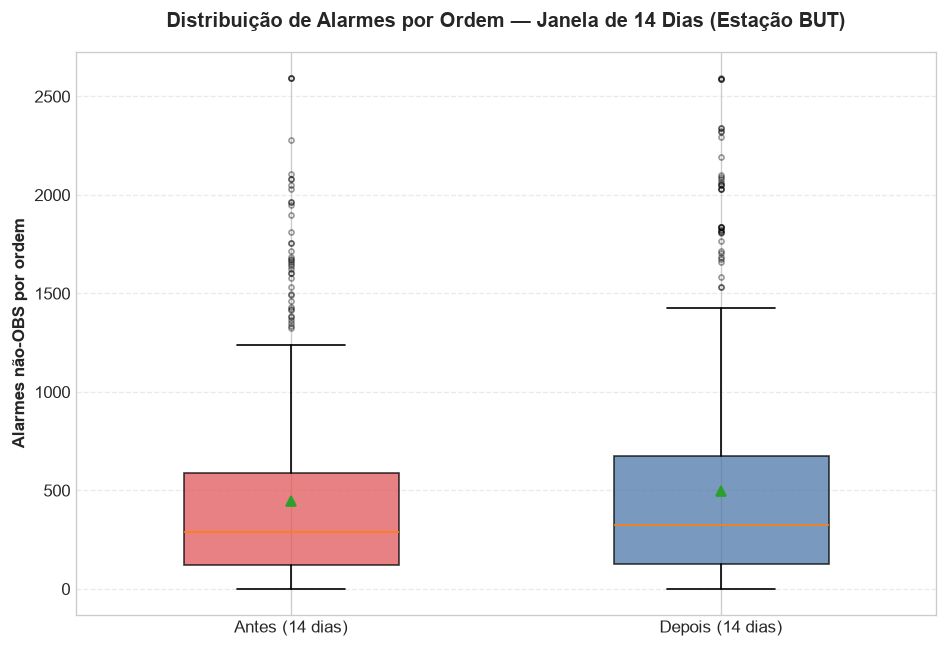

Wilcoxon p-valor (14 dias): 0.0012
Teste binomial p-valor (14 dias): 0.0082


In [7]:
antes_14, depois_14 = distribuicoes[14]

fig, ax = plt.subplots(figsize=(8, 5.5))
caixa = ax.boxplot(
    [antes_14, depois_14],
    tick_labels=['Antes (14 dias)', 'Depois (14 dias)'],
    patch_artist=True, showmeans=True, widths=0.5,
    flierprops=dict(marker='o', markersize=3, alpha=0.4)
)
for patch, cor in zip(caixa['boxes'], [COR_ANTES, COR_DEPOIS]):
    patch.set_facecolor(cor)
    patch.set_alpha(0.75)

ax.set_ylabel('Alarmes não-OBS por ordem', fontsize=10, fontweight='bold')
ax.set_title('Distribuição de Alarmes por Ordem — Janela de 14 Dias (Estação BUT)', fontsize=12, fontweight='bold', pad=15)
ax.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.savefig('../../docs/src/assets/sprints/sprint1/hipotese4-boxplot-14dias.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"Wilcoxon p-valor (14 dias): {resumo_df.loc[resumo_df.janela_dias == 14, 'wilcoxon_p'].values[0]:.4f}")
print(f"Teste binomial p-valor (14 dias): {resumo_df.loc[resumo_df.janela_dias == 14, 'binom_p'].values[0]:.4f}")


### 3.3 O que muda depois da manutenção: análise por tipo de alarme

Para entender melhor por que o volume "depois" supera o "antes" na janela de 14 dias, os alarmes foram decompostos por tipo (`CA`, `CSD`, `FC`, `FO`, `LSD`, `OA`, `STS`).


In [8]:
janela_analise = 14
dt = pd.Timedelta(days=janela_analise)
cobre_janela = (ordens_but['DataInicio'] - dt >= cobertura_inicio) & (ordens_but['DataInicio'] + dt <= cobertura_fim)
sub = ordens_but.loc[cobre_janela, 'DataInicio']

linhas_tipo = []
for tipo in sorted(alarmes_but['Alarme'].unique()):
    ts_tipo = np.sort(alarmes_but.loc[alarmes_but['Alarme'] == tipo, 'Horário do Alarme'].values.astype('datetime64[ns]'))
    def contar(lo, hi, arr=ts_tipo):
        return np.searchsorted(arr, np.datetime64(hi), 'left') - np.searchsorted(arr, np.datetime64(lo), 'left')
    total_antes = sum(contar(t - dt, t) for t in sub)
    total_depois = sum(contar(t, t + dt) for t in sub)
    linhas_tipo.append({
        'tipo_alarme': tipo,
        'total_antes': total_antes,
        'total_depois': total_depois,
        'variacao_pct': (total_depois - total_antes) / total_antes * 100 if total_antes else np.nan,
    })

tipos_df = pd.DataFrame(linhas_tipo).sort_values('total_antes', ascending=False).reset_index(drop=True)
display(tipos_df.style.format({'total_antes': '{:,}', 'total_depois': '{:,}', 'variacao_pct': '{:+.1f}%'}))


,tipo_alarme,total_antes,total_depois,variacao_pct
0,STS,"92,180","90,876",-1.4%
1,LSD,"31,847","37,960",+19.2%
2,FO,"31,385","37,661",+20.0%
3,FC,"30,496","35,930",+17.8%
4,OA,"29,348","34,229",+16.6%
5,CA,"28,148","33,260",+18.2%
6,CSD,"27,641","32,692",+18.3%


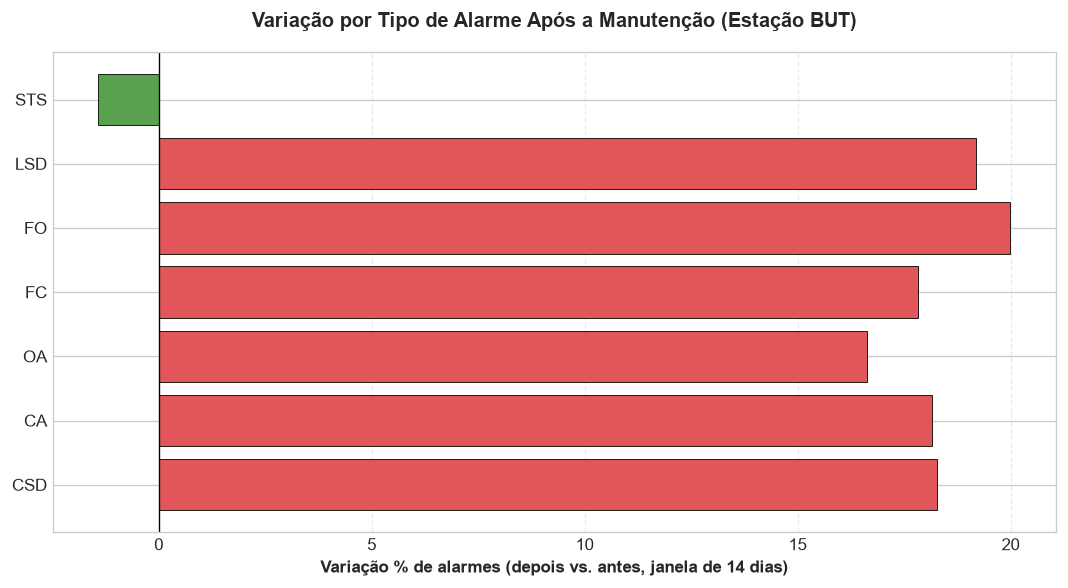

In [9]:
fig, ax = plt.subplots(figsize=(9, 5))
cores_barra = ['#59a14f' if v < 0 else '#e15759' for v in tipos_df['variacao_pct']]
ax.barh(tipos_df['tipo_alarme'], tipos_df['variacao_pct'], color=cores_barra, edgecolor='black', linewidth=0.5)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('Variação % de alarmes (depois vs. antes, janela de 14 dias)', fontsize=10, fontweight='bold')
ax.set_title('Variação por Tipo de Alarme Após a Manutenção (Estação BUT)', fontsize=12, fontweight='bold', pad=15)
ax.grid(axis='x', linestyle='--', alpha=0.4)
ax.invert_yaxis()
plt.tight_layout()
plt.savefig('../../docs/src/assets/sprints/sprint1/hipotese4-tipos-alarme.png', dpi=150, bbox_inches='tight')
plt.show()


## 4. Síntese e Análise Detalhada dos Resultados

Diferentemente da formulação original, os dados **não confirmam** que o volume de alarmes relevantes cresce antes da manutenção corretiva:

1. **Janelas de 1, 3 e 7 dias:** a diferença entre "antes" e "depois" não é estatisticamente significativa (p > 0,05 no teste de Wilcoxon), e a proporção de ordens com mais alarmes antes fica sempre abaixo de 50%.
2. **Janela de 14 dias:** há uma diferença estatisticamente significativa, mas na **direção oposta** à esperada, já que 55,4% das ordens registram mais alarmes *depois* da manutenção do que antes.

Dessa forma, chegamos a conclusão que nenhuma das 4 janelas testadas evidenciam essa hipótese. 
Mas afinal, surge uma dúvida ao analisar os dados, por que o volume para STS é menor depois?

A quebra por tipo de alarme mostra um padrão consistente na janela de 14 dias: os seis tipos de alarme associados a falhas funcionais da porta (`CA`, `CSD`, `FC`, `FO`, `LSD`, `OA`) aumentam entre 16% e 20% depois da manutenção, enquanto o alarme de status (`STS`) permanece praticamente estável (-1,4%).

Isso sugere duas leituras possíveis. Uma delas, é que a manutenção foi realizada de forma incompleta. A manutenção corretiva resolve o sintoma emergencial, mas não elimina a causa raiz, e a porta volta a gerar alarmes funcionais em volume igual ou maior nas semanas seguintes. Outra hipótese é que logo após o reparo, a porta volta a operar em plena carga (após período possivelmente degradado ou parcialmente isolado antes da ordem), o que pode elevar temporariamente a contagem de eventos.

### 4.3 Limitações da análise

Depois de analisar as tabelas, percebemos uma limitação técnica relevante nos dados disponibilizados inicialmente pelo parceiro, onde apenas a estação `BUT` possui alarmes técnicos (não-OBS) registrados na base atual; as demais cinco estações só registram `OBS`. A conclusão acima vale para a estação **Butantã** e não pode ser generalizada às demais estações sem uma base de alarmes mais completa.


## 5. Conclusão

A hipótese de que **alarmes relevantes se intensificam antes de uma manutenção corretiva não encontrou suporte estatístico** nos dados da estação `BUT`, a única com cobertura de alarmes técnicos suficiente para o teste. Em três das quatro janelas avaliadas o resultado é estatisticamente nulo, e na janela mais longa (14 dias) o padrão observado é o **inverso**: alarmes funcionais aumentam depois da intervenção.

Esse achado é relevante para a squad: contradiz a leitura inicial (baseada em uma comparação agregada e não pareada por estação) e aponta para uma questão diferente e mais acionável — se as ordens corretivas de `BUT` estão de fato eliminando a causa raiz das falhas ou apenas normalizando o sintoma temporariamente. Recomenda-se, como próximo passo, cruzar esse resultado com o campo `Causa`/`Ação` das ordens e, quando a cobertura de alarmes técnicos for expandida às demais estações, repetir esta mesma metodologia pareada por estação (e idealmente por porta).
